In [2]:
import pandas as pd
import numpy as np
#%matplotlib widget
%matplotlib inline
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.cosmology import FlatLambdaCDM
from astropy.table import Table, vstack
from astropy.wcs import WCS

import os
from os import getpid

#%matplotlib inline
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm, colors

import mpl_toolkits.mplot3d.art3d as art3d
from matplotlib.patches import Circle, Rectangle

from matplotlib.lines import Line2D

import xspec as x

import matplotlib
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

from scipy import stats
from scipy.optimize import curve_fit

from tqdm.autonotebook import tqdm

import multiprocessing
import datetime

import scipy.odr as odr

from astropy.convolution import convolve, convolve_fft, Gaussian2DKernel, Tophat2DKernel
from IPython.display import clear_output

from skimage.measure import block_reduce
from skimage.transform import resize

### Catalogues of clusters and photon lists:

In [5]:
clusters_all = pd.read_csv("../data/eROSITA_30.0x30.0/Catalouges/cluster.dat", sep='\\s+', header=0)
clusters = clusters_all[clusters_all["M500"]>1e14]
clusters = clusters[clusters["flag"]==0]

wd = "../data/eROSITA_30.0x30.0/Phox/"
mylist = sorted(os.listdir(wd))

phlists = [item for item in mylist if item[:6] == "phlist"]

#print(phlists)

phlists_redshifts = [fits.open(wd+item)[0].header["REDSHIFT"] for item in phlists]#[::-1]

#print(phlists_redshifts)

#clusters

clusters_34 = clusters[clusters["M500"]>1.4e+14]

### Binning clusters:

In [7]:
geometry = pd.read_csv("../data/eROSITA_30.0x30.0/Catalouges/geometry.dat", sep='\\s+', header=2)

binned_clusters = {}
   
for borders in list(zip(geometry["z_start"], geometry["z_end"], geometry["zslice"], geometry["snapNr"])):
    
    for ind in clusters.index:

        zt = clusters.loc[ind]["z_true"]

        if zt > borders[0] and zt < borders[1]:

            binned_clusters[ind] = borders[2], str(borders[3])
                
#sorted(binned_clusters.items())

redshifts = [clusters.loc[i]["z_true"] for i in clusters.index]

#geometry

<Figure size 640x480 with 0 Axes>

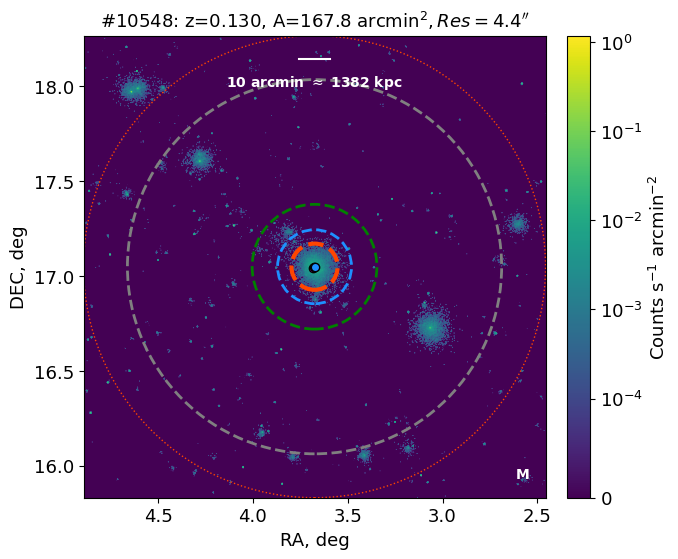

In [54]:
%run -i 'utils/scripts_stacking.py'

plt.figure(figsize=(7,6))
#plt.tight_layout()

cl_num = 10548

#display(clusters[clusters.index==cl_num])

#plt.subplot(121)
pho_hist1 = extract_photons_from_cluster(cl_num, 
                                        r = 1.0, 
                                        centroid=True, 
                                        delete_superfluous=False, 
                                        draw=True,
                                        histlen=2001,
                                        withagn=False, 
                                        ARF_weights=True)



#plt.savefig(str(cl_num)+'.pdf', format='pdf', dpi=100, bbox_inches='tight')

plt.show()

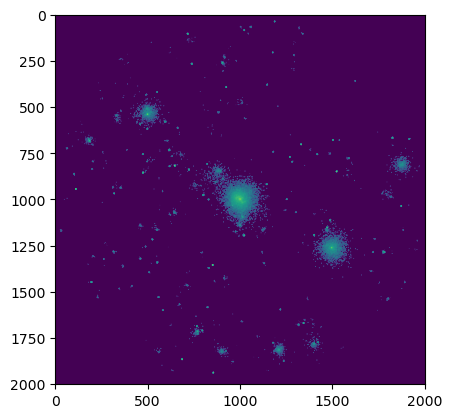

In [55]:
length = len(pho_hist1) #   2001

half_length = int(length/2)
r500r1 = int(half_length/10)

pho_hist1 = pho_hist1*create_circle_mask(half_length, half_length, half_length, length)

plt.imshow(pho_hist1, origin='upper', norm=matplotlib.colors.SymLogNorm(linthresh=0.0001, linscale=1))

In [57]:
from scipy.ndimage import rotate

def rotate_image_clockwise(image, alpha_deg, order=3, fill_value=np.nan):
    """
    Rotate a 2D image clockwise by alpha_deg, measured from the +x direction.
    """
    return rotate(
        image,
        angle=alpha_deg,      # negative => clockwise
        axes=(1, 0),           # rotate in the (x, y) image plane
        reshape=False,         # keep 2000 x 2000 output shape
        order=0,           # 1=bilinear, 3=cubic spline
        mode="constant",
        #cval=fill_value,
        cval=0.0,           # fill empty corners with 0
        prefilter=True,
    )

image1 = pho_hist1

rotated1 = rotate_image_clockwise(image1, alpha_deg=30)

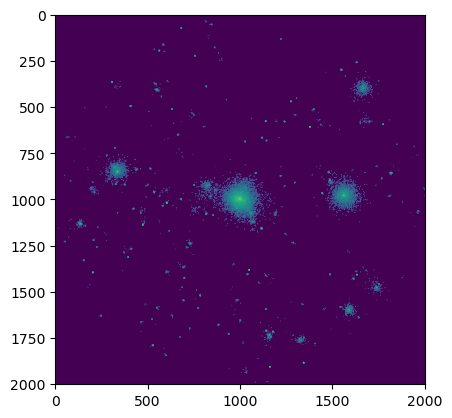

In [58]:
plt.imshow(rotated1, origin='upper', norm=matplotlib.colors.SymLogNorm(linthresh=0.0001, linscale=1))

In [60]:
#rotated2 = rotate_image_clockwise(rotated, alpha_deg=-30.0)

In [61]:
#plt.imshow(rotated2, origin='upper', norm=matplotlib.colors.SymLogNorm(linthresh=0.0001, linscale=1))

<Figure size 640x480 with 0 Axes>

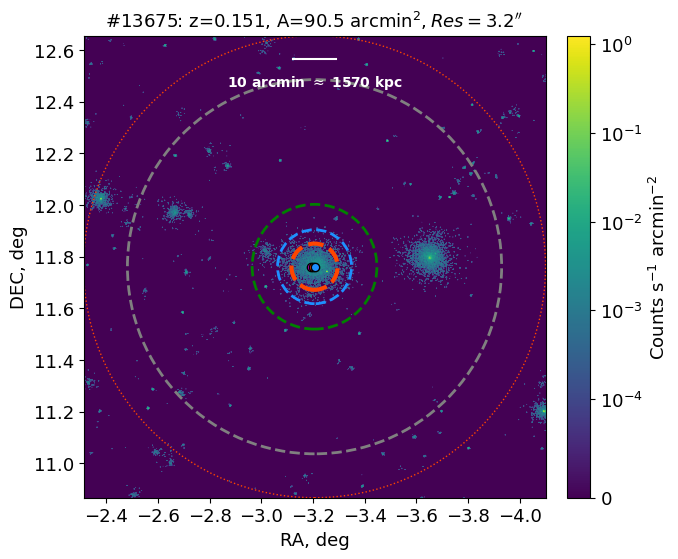

In [62]:
%run -i 'utils/scripts_stacking.py'

plt.figure(figsize=(7,6))
#plt.tight_layout()

cl_num = 13675

#display(clusters[clusters.index==cl_num])

#plt.subplot(121)
pho_hist2 = extract_photons_from_cluster(cl_num, 
                                        r = 1.0, 
                                        centroid=True, 
                                        delete_superfluous=False, 
                                        draw=True,
                                        histlen=2001,
                                        withagn=False, 
                                        ARF_weights=True)

#plt.savefig(str(cl_num)+'.pdf', format='pdf', dpi=100, bbox_inches='tight')

plt.show()

In [65]:
pho_hist2 = pho_hist2*create_circle_mask(half_length, half_length, half_length, length)

rotated2 = rotate_image_clockwise(pho_hist2, alpha_deg=0)

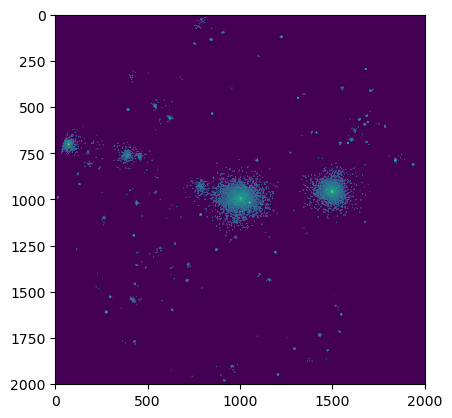

In [66]:
plt.imshow(rotated2, origin='upper', norm=matplotlib.colors.SymLogNorm(linthresh=0.0001, linscale=1))

In [67]:
%run -i 'utils/scripts_stacking.py'

brbr1= brightness_profile(clusternumber=19787,   # choose any
                          hist=pho_hist1, 
                          mmmask='no',
                          draw=False,
                          field_length=20,
                          ARF_weights=True,
                          errors=True)

  0%|          | 0/23 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>

In [75]:
%run -i 'utils/scripts_stacking.py'

brbr2= brightness_profile(clusternumber=19787,   # choose any
                          hist=pho_hist2,    
                          mmmask='no',
                          draw=False,
                          field_length=20,
                          ARF_weights=True,
                          errors=True)

  0%|          | 0/23 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>

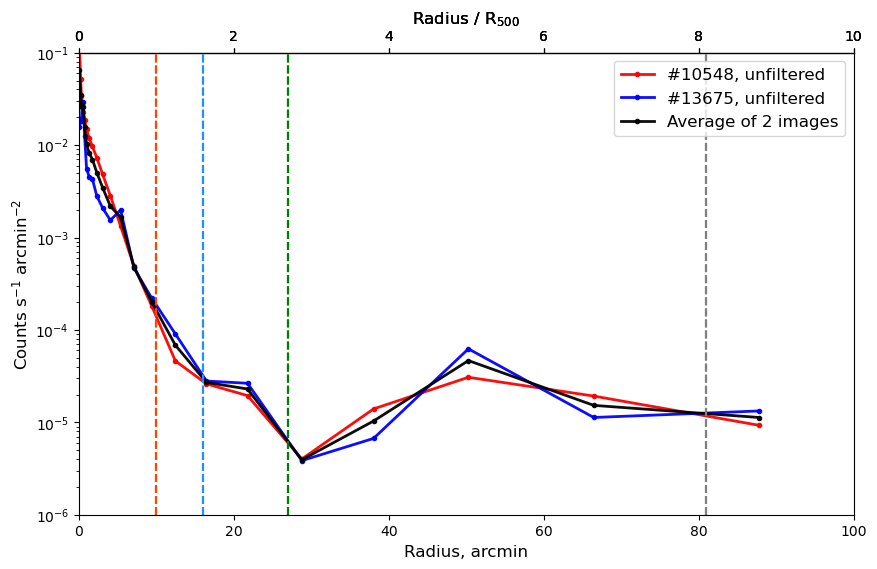

In [108]:
%run -i 'utils/scripts_stacking.py'
%run -i 'utils/draw_stacking.py'

plt.figure(figsize=(10, 6))

bkg=0
wedges4_1 = draw_stacked_profile(brbr1[0], brbr1[1], brbr1[4], brbr1[5], brbr1[6], bkg, 'r', '#10548, unfiltered')
wedges4_2 = draw_stacked_profile(brbr2[0], brbr2[1], brbr2[4], brbr2[5], brbr2[6], bkg, 'b', '#13675, unfiltered')

wedges4_3 = draw_stacked_profile(brbr3[0], brbr3[1], brbr3[4], brbr3[5], brbr3[6], bkg, 'k', 'Average of 2 images')

plt.xlim(1e-10,100)
plt.ylim(10**(-6), 10**(-1))
plt.xscale("linear")

plt.legend(loc=1, fontsize=12)

plt.show()

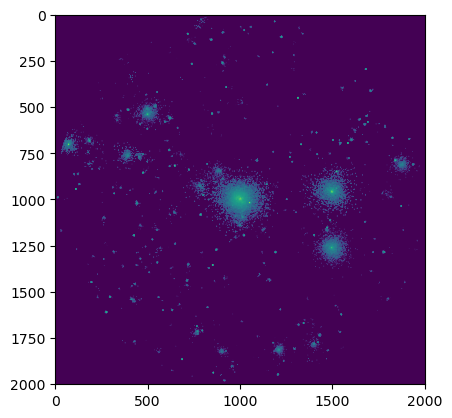

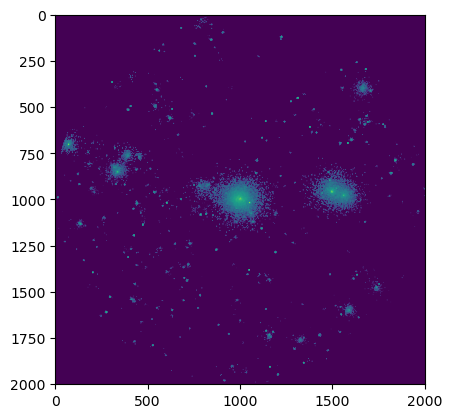

In [106]:
pho_hist3 = (pho_hist1+pho_hist2)/2
rotated3 = (rotated1+rotated2)/2

plt.imshow(pho_hist3, origin='upper', norm=matplotlib.colors.SymLogNorm(linthresh=0.0001, linscale=1))
plt.show()
plt.imshow(rotated3, origin='upper', norm=matplotlib.colors.SymLogNorm(linthresh=0.0001, linscale=1))
plt.show()

In [107]:
%run -i 'utils/scripts_stacking.py'

brbr3= brightness_profile(clusternumber=19787,   # choose any
                          hist=pho_hist3,    
                          mmmask='no',
                          draw=False,
                          field_length=20,
                          ARF_weights=True,
                          errors=True)

  0%|          | 0/23 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>